# Supervised and unsupervised learning!

## 🗂️ Project structure

1. Following the task description, you'll find a set of formal requirements that your solution must meet.
2. The primary measure of your success is the **test** performance of your model, as specified in each problem.
3. After completing each task, you must answer a series of questions, marked with ❓, to demonstrate your understanding of the techniques used.
4. You may create as many cells as needed, but the final results should be kept in a short and simple cell.

## 📝 Submission guidelines

- For each problem, provide your code solution and model results inside this notebook.
- Answer the follow-up questions in markdown format within this notebook. A few sentences is enough, no requirements for length of answers.
- Ensure your explanations are clear, concise, and demonstrate a deep understanding of the techniques employed.
- Submit this notebook (**problem.ipynb**) to Canvas. Deliver the notebook such that outputs are saved, ideally *restart* the kernel followed by *run all*.
- Use Kaggle to check your cluster assignments while you work. More details are in the problem description.
- Include your final **submission.csv** in the Canvas delivery, together with this notebook.

Good luck!

---


# 🎯 Problem 1: Training Neural Networks

### ❗️ The problem

Train neural networks for:
- A binary classification problem
- A non-linear regression problem

To reach the target performance, you may want to experiment with optimization techniques such as:
- Full-batch vs. mini-batch training
- Learning-rate scheduling (e.g., cosine annealing)
- Hyperparameter tuning (learning rate, batch size, depth, width)
- Optimizers (e.g., Adam, RMSprop, SGD)
- Activation functions (e.g., sigmoid, tanh, ReLU, GELU)
- Early stopping
- And more!

### 📋 Formal requirements

1. **Implementation**
   - Use Tensorflow/Keras or PyTorch for each problem (for Keras, you may find these guides useful: [Sequential model](https://keras.io/guides/sequential_model/) and [Training with built-in methods](https://keras.io/guides/training_with_built_in_methods/))
   - Try **at least three** of the techniques listed above.
   - Results must be **reproducible**: rerunning the notebook should yield the same metrics (fix random seeds).

2. **Performance**
   - **Classification**: at least **90% accuracy on the test set**.
   - **Regression**: at most **0.25 RMSE** on the test inputs, scored by `plot_complex_fit`.

3. **Discussion**
   - How did you ensure reproducibility?
   - Visualize/explain the network architecture for both classification and regression (e.g., block diagram, parameter counts, activation functions, etc.).
   - Plot the classification **decision boundary** with `plot_decision_boundary` from `utils`. Would the model generalize to larger feature values?
   - Plot train and held-out loss vs. epoch for classification and for regression. What do these curves tell you? Are the final values a good way to judge the model performance?
   - Which optimization techniques did you try? What worked and what did not?


In [58]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN, KMeans
from utils import plot_complex_fit, plot_decision_boundary
# Any other imports you need
import os
os.environ["KERAS_BACKEND"] = 'torch'
import keras
import tensorflow
from keras import layers
from keras import ops

tensorflow.keras.utils.set_random_seed(42)  # sets seeds for base-python, numpy and tf
tensorflow.config.experimental.enable_op_determinism()

## Binary classification


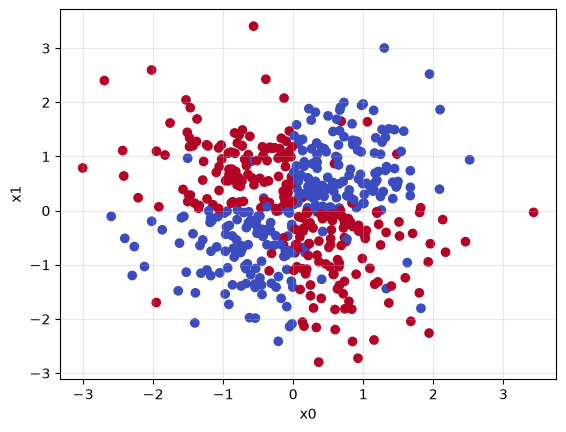

In [16]:
# This is our problem... It's basically XOR, but with continuous values (and a lot of noise!)
data = pd.read_csv("classification_data.csv")
train = data[data["split"] == "train"]
test = data[data["split"] == "test"]

plt.scatter(test["x0"], test["x1"], c=test["y"], cmap="coolwarm")
plt.xlabel("x0")
plt.ylabel("x1")
plt.grid(True, alpha=0.3)
plt.show()

In [39]:
# ====================================
# YOUR CODE GOES HERE
# ====================================
x_train = train[['x0','x1']]
y_train = train['y']
x_test = test[['x0', 'x1']]
y_test = test['y']

# RELU
model_relu = keras.Sequential([
    keras.Input(shape=(2,), name="inputs"), # input

    layers.Dense(2, activation='relu', name = "layer1"),
    layers.Dense(3, activation='relu', name = "layer2"),
    layers.Dense(4, activation='relu', name = "layer3"),
    layers.Dense(5, activation='relu', name = "layer4"),
    layers.Dense(6, activation='relu', name = "layer5"),
    layers.Dense(7, activation='relu', name = "layer6"),

    layers.Dense(1, activation = "sigmoid", name = "predictions") #output
])
model_relu.compile(
    optimizer=keras.optimizers.RMSprop(learning_rate=0.01),  # Optimizer
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[keras.metrics.BinaryAccuracy()],
)

history = model_relu.fit(
    x_train, y_train, validation_split=0.1,verbose = 0,
    batch_size=64,
    epochs=100,
)
print(f'RELU: test loss, test acc = {model_relu.evaluate(x_test,y_test)}')


# tanh
model_tanh = keras.Sequential([
    keras.Input(shape=(2,), name="inputs"), # input

    layers.Dense(2, activation='tanh', name = "layer1"),
    layers.Dense(3, activation='tanh', name = "layer2"),
    layers.Dense(4, activation='tanh', name = "layer3"),
    layers.Dense(5, activation='tanh', name = "layer4"),
    layers.Dense(6, activation='tanh', name = "layer5"),
    layers.Dense(7, activation='tanh', name = "layer6"),

    layers.Dense(1, activation = "sigmoid", name = "predictions") #output
])
model_tanh.compile(
    optimizer=keras.optimizers.RMSprop(learning_rate=0.01),  # Optimizer
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[keras.metrics.BinaryAccuracy()],
)

history = model_tanh.fit(
    x_train, y_train, validation_split=0.1,verbose = 0,
    batch_size=64,
    epochs=100,
)
print(f'tanh: test loss, test acc = {model_tanh.evaluate(x_test,y_test)}')



# sigmoid
model_sigmoid = keras.Sequential([
    keras.Input(shape=(2,), name="inputs"), # input

    layers.Dense(2, activation='sigmoid', name = "layer1"),
    layers.Dense(3, activation='sigmoid', name = "layer2"),
    layers.Dense(4, activation='sigmoid', name = "layer3"),
    layers.Dense(5, activation='sigmoid', name = "layer4"),
    layers.Dense(6, activation='sigmoid', name = "layer5"),
    layers.Dense(7, activation='sigmoid', name = "layer6"),

    layers.Dense(1, activation = "sigmoid", name = "predictions") #output
])
model_sigmoid.compile(
    optimizer=keras.optimizers.RMSprop(learning_rate=0.01),  # Optimizer
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[keras.metrics.BinaryAccuracy()],
)

history = model_sigmoid.fit(
    x_train, y_train, validation_split=0.1,verbose = 0,
    batch_size=64,
    epochs=100,
)
print(f'sigmoid: test loss, test acc = {model_sigmoid.evaluate(x_test,y_test)}')


16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9000 - loss: 0.2979 
RELU: test loss, test acc = [0.2978982627391815, 0.8999999761581421]
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - binary_accuracy: 0.9020 - loss: 0.2931 
tanh: test loss, test acc = [0.293098121881485, 0.9020000100135803]
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.5180 - loss: 0.6934 
sigmoid: test loss, test acc = [0.6933615803718567, 0.5180000066757202]


### ❓ Visualize the network architecture for both classification and regression.


In [40]:
print("Classification model:")
model_tanh.summary()

Classification model:


Model: "sequential_31"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ layer1 (Dense)                  │ (None, 2)              │             6 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer2 (Dense)                  │ (None, 3)              │             9 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer3 (Dense)                  │ (None, 4)              │            16 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer4 (Dense)                  │ (None, 5)              │            25 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer5 (Dense)                  │ (None, 6)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer6 (Dense)                  │ (None, 7)              │            49 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 1)              │             8 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 300 (1.18 KB)

 Trainable params: 149 (596.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 151 (608.00 B)

### ❓ Plot the classification decision boundary. Would the model generalize to larger feature values?

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


(<Figure size 600x400 with 1 Axes>,
 <Axes: title={'center': 'Decision boundary'}, xlabel='x0', ylabel='x1'>)

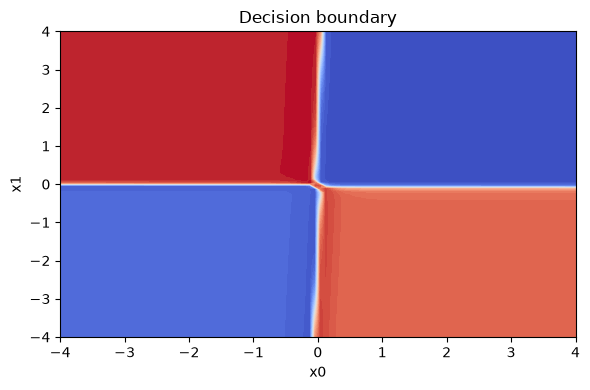

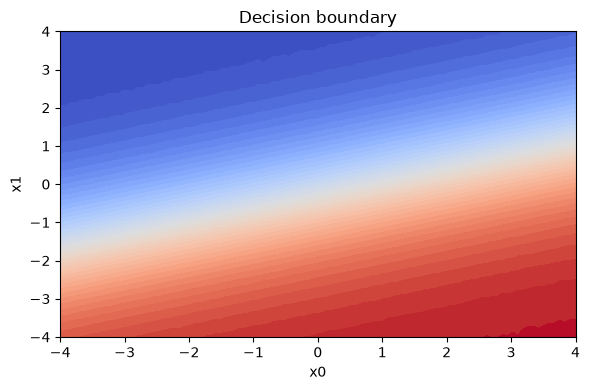

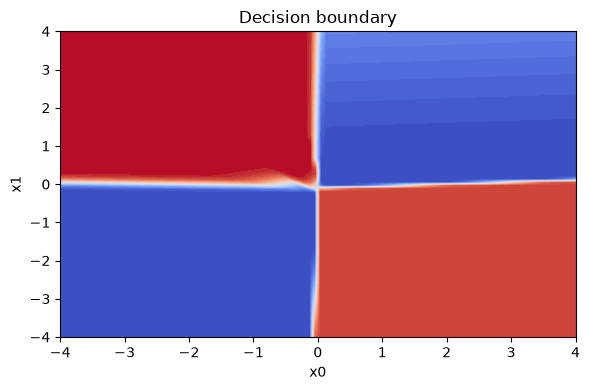

In [47]:
plot_decision_boundary(model_tanh.predict)
plot_decision_boundary(model_sigmoid.predict)
plot_decision_boundary(model_relu.predict)

## Regression


In [57]:
# We have a new dataset now. This time, the target is continuous.
# Test rows have no y. For a validation split, hold out part of train.
data = pd.read_csv("regression_data.csv")
train = data[data["split"] == "train"]
test = data[data["split"] == "test"]
data.describe()
# plt.scatter(train["x0"], train["x1"], c=train["y"], cmap="coolwarm")
# plt.xlabel("x0")
# plt.ylabel("x1")
# plt.title("Training samples")
# plt.grid(True, alpha=0.3)
# plt.show()

,x0,x1,y
count,500.000000,500.000000,400.000000
mean,0.123040,0.012211,0.130722
std,1.153935,1.122107,4.781687
min,-1.998797,-1.999240,-15.364323
25%,-0.829806,-0.938190,-1.939314
50%,0.232053,-0.000105,0.275004
75%,1.144455,1.013061,2.437497
max,1.988840,1.998005,15.641089


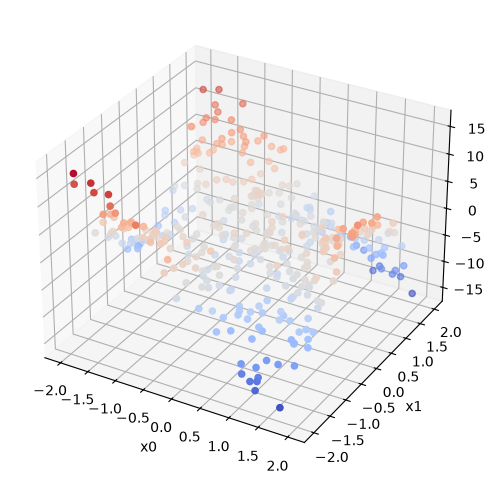

In [54]:
# Hmmm, maybe 3d is better
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(train["x0"], train["x1"], train["y"], c=train["y"], cmap="coolwarm")
ax.set_xlabel("x0")
ax.set_ylabel("x1")
ax.set_zlabel("y")
plt.show()

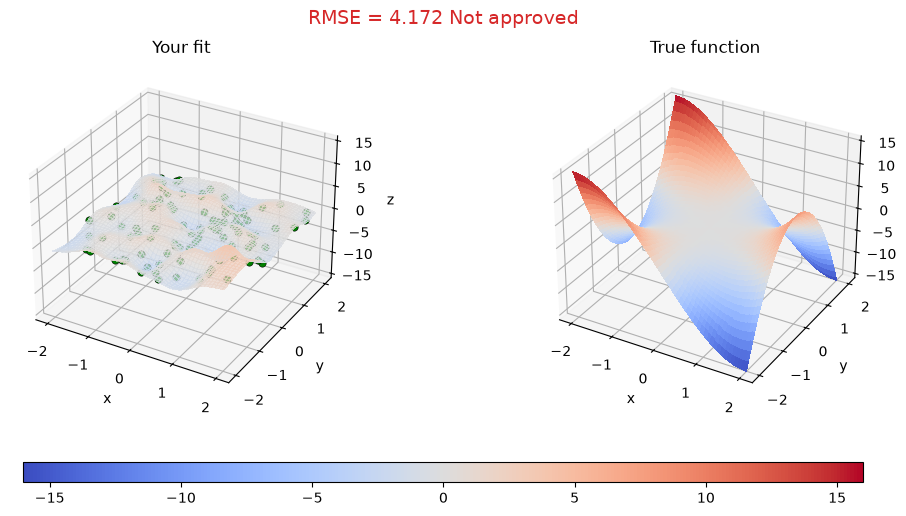

In [55]:
# plot_complex_fit compares your predictions to the true surface and prints RMSE
# plot_complex_fit has no noise, so expect a lower RMSE here
# The test rows have no y, so this is how you score them.
test_xy = test[["x0", "x1"]].values
y_pred_demo = np.random.randn(len(test))
plot_complex_fit(test_xy, y_pred_demo)
plt.show()

# Random predictions fail the 0.25 RMSE threshold.

In [60]:
# ====================================
# YOUR CODE GOES HERE
# ====================================
data = pd.read_csv("regression_data.csv")
train = data[data["split"] == "train"]
test = data[data["split"] == "test"]
# data.describe()
x_train = train[['x0','x1']]
y_train = train['y']
x_test = test[['x0', 'x1']]
y_test = test['y']


In [61]:
model_tanh = keras.Sequential([
    keras.Input(shape=(2,), name="inputs"), # input

    layers.Dense(2, activation='tanh', name = "layer1"),
    layers.Dense(3, activation='tanh', name = "layer2"),
    layers.Dense(4, activation='tanh', name = "layer3"),
    layers.Dense(5, activation='tanh', name = "layer4"),
    layers.Dense(6, activation='tanh', name = "layer5"),
    layers.Dense(7, activation='tanh', name = "layer6"),

    layers.Dense(1, name = "predictions") #output
])
model_tanh.compile(
    optimizer=keras.optimizers.RMSprop(learning_rate=0.01),  # Optimizer
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[keras.metrics.SparseCategoricalAccuracy()],
)

history = model_tanh.fit(
    x_train, y_train, validation_split=0.1,verbose = 0,
    batch_size=32,
    epochs=100,
)

InvalidArgumentError: Graph execution error:

Detected at node compile_loss/sparse_categorical_crossentropy/SparseSoftmaxCrossEntropyWithLogits/GatherV2 defined at (most recent call last):
  File "<frozen runpy>", line 198, in _run_module_as_main

  File "<frozen runpy>", line 88, in _run_code

  File "c:\Users\saavi\miniconda3\envs\intro_ml\Lib\site-packages\ipykernel_launcher.py", line 18, in <module>

  File "c:\Users\saavi\miniconda3\envs\intro_ml\Lib\site-packages\traitlets\config\application.py", line 1082, in launch_instance

  File "c:\Users\saavi\miniconda3\envs\intro_ml\Lib\site-packages\ipykernel\kernelapp.py", line 807, in start

  File "c:\Users\saavi\miniconda3\envs\intro_ml\Lib\site-packages\tornado\platform\asyncio.py", line 211, in start

  File "c:\Users\saavi\miniconda3\envs\intro_ml\Lib\asyncio\base_events.py", line 645, in run_forever

  File "c:\Users\saavi\miniconda3\envs\intro_ml\Lib\asyncio\base_events.py", line 1999, in _run_once

  File "c:\Users\saavi\minico

In [ ]:
print(f'tanh: test loss, test acc = {model_tanh.evaluate(x_test,y_test)}')
preds = model_tanh.predict(x_test)
plot_complex_fit(test_xy, preds)
plt.show()

### ❓ Plot train and held-out loss vs. epoch. What do these curves tell you? Are the final values a good way to judge the model?


### ❓ Which optimization techniques did you try? What worked and what did not?


### ❓ How did you ensure reproducibility?

# 🤖 Problem 2: Unsupervised Learning

### ❗️ The problem

1. Identify the number of clusters in the dataset.
2. Assign a cluster label to every row and validate on [Kaggle](https://www.kaggle.com/t/bce19782f3e4447e9bc9de37f36cee86) until you reach at least **99%** clustering accuracy.
3. Visualize the clusters in 2D, and identify what each cluster is.
4. Some rows do not belong with the others. Find those rows and show what they are.

### 💡 Hints

1. **Large Dataset**: The data set **unsupervised_data.csv** is huge! There are many features, dimensionality reduction can help.
2. **Unsupervised Learning**: No target labels are provided, patterns must come from the features alone.
3. **Data Obfuscation**: The data has a structured format. Try to find the meaning and correct ordering of the features.

### 📚 Resources

- [Clustering in scikit-learn](https://scikit-learn.org/stable/modules/clustering.html) (KMeans, DBSCAN, …)
- [Manifold learning](https://scikit-learn.org/stable/modules/manifold.html) (PCA, t-SNE, …)
- Feel free to use any other methods you find in the scikit-learn documentation!
- Kaggle competition (50 submissions per day)

### 📋 Formal requirements

1. Identify the number of clusters in the dataset.
2. Reach at least **99%** clustering accuracy on Kaggle.
3. Visualize the clusters in 2D.
4. Identify what each cluster corresponds to.
5. Some rows do not belong here, perform anomaly detection and find those samples.
6. **Discussion**
   - Which dimensionality reduction methods helped you choose *k*? Compare PCA and t-SNE in 2D.
   - Which clustering algorithm and hyperparameters did you use? Compare KMeans and DBSCAN.
   - What is the hidden modality? How does this impact dimensionality reduction and clustering?
   - List the facilities in Trondheim and how you identified them.
   - How did you detect the rows that do not belong, and what were they?

## 🏆 Kaggle

Kaggle is a popular platform for machine learning competitions. It allows hosts to share datasets while keeping the labels hidden from the participants. The clustering labels are not available locally. Use **Kaggle** to check your cluster assignments.

- Invitation: https://www.kaggle.com/t/bce19782f3e4447e9bc9de37f36cee86
- Upload a CSV with columns `ID` and `cluster` (integer cluster ids) to check your score.
- Also include the final **submission.csv** in your Canvas delivery, together with the notebook.


In [8]:
# Why did we skip the first row? Maybe it's useful metadata for later...
data = pd.read_csv("unsupervised_data.csv", skiprows=1, header=None)
data = data.reset_index(names="ID")
data

,ID,0,1,2,3,4,5,6,7,8,...,16374,16375,16376,16377,16378,16379,16380,16381,16382,16383
0,0,0.314365,0.646305,0.323849,0.238492,0.655790,0.646305,0.646305,0.409205,0.646305,...,0.646305,0.646305,0.655790,0.238492,0.646305,0.674758,0.646305,0.238492,0.655790,0.646305
1,1,0.587628,0.494976,0.559832,-0.246237,0.513506,0.550567,0.522772,0.596893,0.606158,...,0.587628,0.550567,0.587628,0.587628,0.550567,0.587628,0.550567,0.596893,0.494976,0.587628
2,2,0.590203,0.367673,0.367673,0.367673,0.367673,0.590203,0.367673,0.590203,0.590203,...,0.590203,0.367673,0.590203,0.590203,0.590203,0.590203,0.590203,0.590203,0.590203,0.476556
3,3,0.589296,0.589296,0.579825,0.551415,0.579825,0.579825,0.608236,0.579825,0.646118,...,0.532474,0.523003,0.589296,0.589296,0.551415,0.134721,0.475652,0.589296,0.570355,0.551415
4,4,0.660095,0.470676,0.190366,0.672806,0.470761,0.672766,0.672652,0.666151,0.672987,...,0.432001,0.672222,0.190568,0.217329,0.633684,0.673294,0.587914,0.671023,0.207578,0.470765
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3995,3995,0.340739,0.340739,0.340739,0.681823,0.340739,0.340739,0.340739,0.672083,0.340739,...,0.340739,0.662355,0.340739,0.759779,0.331011,0.759779,0.340739,0.691563,0.340734,0.720789
3996,3996,0.384257,0.384257,0.675221,0.384257,0.384257,0.675221,0.384257,0.675221,0.675221,...,0.675221,0.384257,0.675221,0.675221,0.675221,0.384257,0.384257,0.384257,0.675221,0.675221
3997,3997,0.641837,0.651135,0.251329,0.251329,0.651135,0.651135,0.251329,0.651135,0.651135,...,0.251329,0.251329,0.651135,0.251329,0.409392,0.604646,0.651135,0.651135,0.660433,0.251329
3998,3998,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,-0.212897,0.555533,...,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533


In [9]:
# Probably too many columns for naive clustering on raw pixels
data.info(max_cols=5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Columns: 16385 entries, ID to 16383
dtypes: float64(16384), int64(1)
memory usage: 500.0 MB


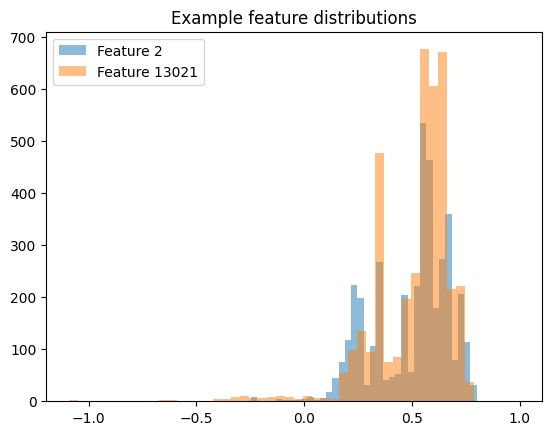

In [10]:
features = data.drop(columns="ID")
plt.hist(features.iloc[:, 2], bins=50, alpha=0.5, label="Feature 2")
plt.hist(features.iloc[:, 13021], bins=50, alpha=0.5, label="Feature 13021")
plt.legend()
plt.title("Example feature distributions")
plt.show()

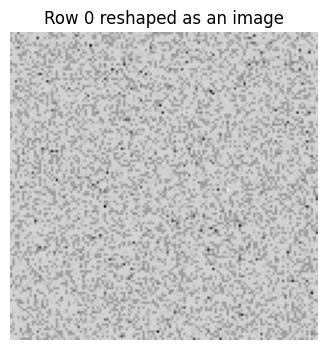

In [11]:
# 16384 = 128 × 128. Coincidence? This may be a flattened grayscale image...
row = data.iloc[0, 1:].astype(float).to_numpy()
image = row.reshape(128, 128).T
image = (image - image.min()) / (image.max() - image.min() + 1e-8)

plt.figure(figsize=(4, 4))
plt.imshow(image, cmap="gray")
plt.title("Row 0 reshaped as an image")
plt.axis("off")
plt.show()

# If it really is an image, then pixels look scrambled.
# The true order may be encoded elsewhere. Maybe the dropped row contained important information?

In [12]:
# Kaggle submission format. The cluster ids here are just placeholders and do not hint at k.
sample_submission = pd.read_csv("sample_submission.csv")
sample_submission.head()

,ID,cluster
0,0,2
1,1,6
2,2,3
3,3,3
4,4,8


In [13]:
# ====================================
# YOUR CODE GOES HERE
# ====================================

### ❓ Which dimensionality reduction methods helped you choose *k*? Compare PCA and t-SNE in 2D.


### ❓ Which clustering algorithm and hyperparameters did you use? Compare KMeans and DBSCAN.


### ❓ What is the hidden modality? How does this impact dimensionality reduction and clustering?


### ❓ List the facilities in Trondheim and how you identified them.

### ❓ How did you detect the rows that do not belong, and what were they?


---

## Note: Clustering accuracy metric

Kaggle scores clustering with **label-invariant** accuracy: only the grouping matters, not the numeric ids.

If true labels are `[0, 0, 0, 1, 1, 1]` and you predict `[1, 1, 1, 0, 0, 0]`, accuracy is **1.0** because clusters match after renaming.

### How it is computed

1. Build a contingency matrix between true and predicted labels.
2. Find the best label matching (Hungarian algorithm / `linear_sum_assignment`).
3. Accuracy = matched points / total points.

---

In [14]:
import scipy.optimize
import sklearn.metrics


def calculate_clustering_accuracy(true_labels: np.ndarray, cluster_labels: np.ndarray) -> float:
    """Clustering accuracy with optimal permutation of cluster ids."""
    if true_labels.size != cluster_labels.size:
        raise ValueError("true_labels and cluster_labels must have the same length.")

    contingency = sklearn.metrics.cluster.contingency_matrix(true_labels, cluster_labels)
    row_ind, col_ind = scipy.optimize.linear_sum_assignment(-contingency)
    correct = contingency[row_ind, col_ind].sum()
    return correct / true_labels.size

In [15]:
true_labels = np.array([0, 1, 2, 0, 1, 2])
cluster_labels = np.array([1, 2, 0, 1, 2, 0])
calculate_clustering_accuracy(true_labels, cluster_labels)

np.float64(1.0)

In [16]:
# Single cluster in ground truth: accuracy is share of majority predicted cluster
true_labels = np.array([0, 0, 0, 0, 0, 0])
cluster_labels = np.array([1, 2, 0, 1, 2, 0])
calculate_clustering_accuracy(true_labels, cluster_labels)

np.float64(0.3333333333333333)

In [17]:
# Wrong number of groups: low accuracy
true_labels = np.array([1, 1, 1, 2, 2, 2])
cluster_labels = np.array([0, 0, 0, 0, 0, 0])
calculate_clustering_accuracy(true_labels, cluster_labels)

np.float64(0.5)